# Task 1


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [10]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

Train size: 60000, Test size: 10000


In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, stride=1, padding=2), # output: 16x28x28
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 16x14x14
            nn.Conv2d(16, 32, kernel_size=5, stride=1, padding=2), # output: 32x14x14
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # output: 32x7x7
        )
        self.fc_layers = nn.Sequential(
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)
        x = self.fc_layers(x)
        return x

model = BaselineCNN().to(device)
print(model)

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 2
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs} Loss: {epoch_loss:.4f}")

Epoch 1/2 Loss: 0.0384
Epoch 2/2 Loss: 0.0262


In [6]:
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

clean_acc = evaluate_accuracy(model, test_loader)
print(f"Clean test accuracy: {clean_acc:.1f} %")

Clean test accuracy: 98.8 %


# Tasks 2, 3, and 6: Adversarial Attacks (FGSM & PGD) & Performance Evaluation

In [15]:
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def pgd_attack(model, image, label, epsilon, alpha=None, num_iter=10):
    if alpha is None:
        alpha = epsilon / 4
    perturbed_image = image.clone().detach() + torch.FloatTensor(*image.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_image = torch.clamp(perturbed_image, 0, 1)

    for i in range(num_iter):
        perturbed_image.requires_grad = True
        outputs = model(perturbed_image)
        loss = nn.CrossEntropyLoss()(outputs, label)
        model.zero_grad()
        loss.backward()


        adv_image = perturbed_image + alpha * perturbed_image.grad.sign()
        eta = torch.clamp(adv_image - image, min=-epsilon, max=epsilon)
        perturbed_image = torch.clamp(image + eta, min=0, max=1).detach()

    return perturbed_image

In [16]:
def evaluate_attack(model, loader, epsilon, attack_type="fgsm"):
    model.eval()
    correct = 0
    total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if epsilon == 0:
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            continue

        if attack_type == "fgsm":
            images.requires_grad = True
            outputs = model(images)
            loss = nn.CrossEntropyLoss()(outputs, labels)
            model.zero_grad()
            loss.backward()
            data_grad = images.grad.data
            perturbed_images = fgsm_attack(images, epsilon, data_grad)
        elif attack_type == "pgd":
            perturbed_images = pgd_attack(model, images, labels, epsilon)

        outputs = model(perturbed_images)
        _, predicted = torch.max(outputs.data, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return 100 * correct / total

In [17]:
epsilons = [0.0, 0.05, 0.10, 0.20, 0.30]
fgsm_accs = []
pgd_accs = []

print("EPSILON\tFGSM_ACC\tPGD_ACC")
print("-------------------------------")
for eps in epsilons:
    fgsm_acc = evaluate_attack(model, test_loader, eps, "fgsm")
    pgd_acc = evaluate_attack(model, test_loader, eps, "pgd")
    fgsm_accs.append(fgsm_acc)
    pgd_accs.append(pgd_acc)
    print(f"{eps:.2f}\t{fgsm_acc:.1f} %\t{pgd_acc:.1f} %")
print("-------------------------------")

EPSILON	FGSM_ACC	PGD_ACC
-------------------------------
0.00	99.0 %	99.0 %
0.05	94.0 %	91.7 %
0.10	77.8 %	53.8 %
0.20	24.0 %	0.2 %
0.30	4.7 %	0.0 %
-------------------------------


# Task 4: Display Clean vs. Adversarial Digits

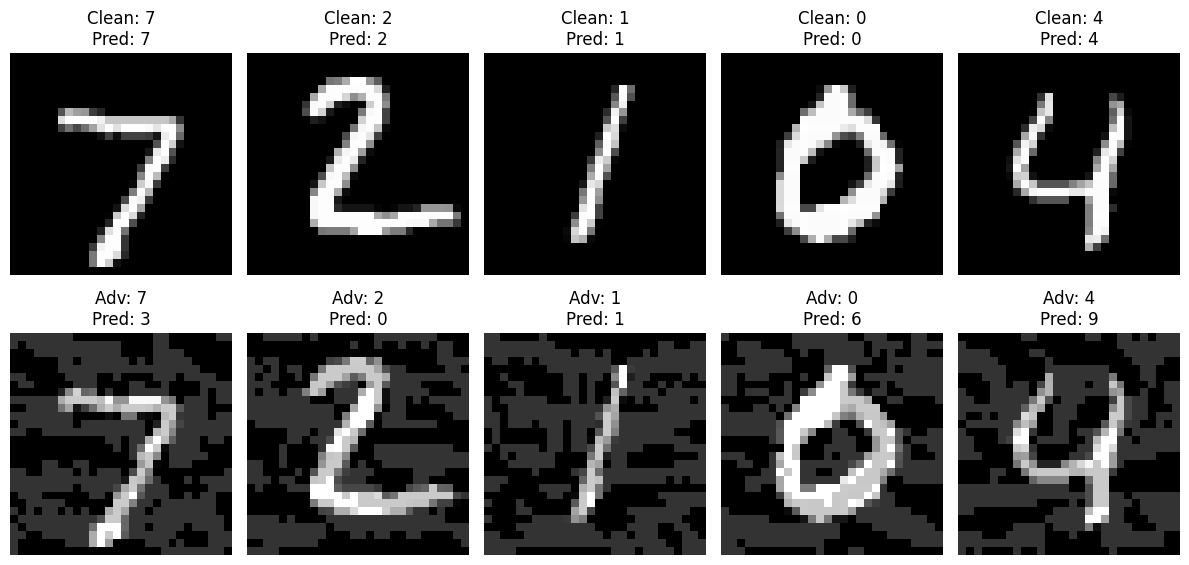

In [18]:
model.eval()
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
images.requires_grad = True
outputs = model(images)
loss = nn.CrossEntropyLoss()(outputs, labels)
model.zero_grad()
loss.backward()
data_grad = images.grad.data
perturbed_images = fgsm_attack(images, 0.20, data_grad)
with torch.no_grad():
    clean_outputs = model(images)
    _, clean_preds = torch.max(clean_outputs, 1)
    adv_outputs = model(perturbed_images)
    _, adv_preds = torch.max(adv_outputs, 1)

for i in range(5):
    axes[0, i].imshow(images[i].cpu().detach().squeeze(), cmap='gray')
    axes[0, i].set_title(f"Clean: {labels[i].item()}\nPred: {clean_preds[i].item()}")
    axes[0, i].axis('off')
    axes[1, i].imshow(perturbed_images[i].cpu().detach().squeeze(), cmap='gray')
    axes[1, i].set_title(f"Adv: {labels[i].item()}\nPred: {adv_preds[i].item()}")
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig("clean_vs_adversarial.png")
plt.show()

# Task 5: Adversarial Training

In [19]:
adv_model = BaselineCNN().to(device)
adv_model.load_state_dict(model.state_dict())
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

epochs = 2
for epoch in range(epochs):
    adv_model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        batch_size = images.size(0)
        half_batch = batch_size // 2

        clean_images = images[:half_batch]
        clean_labels = labels[:half_batch]

        adv_inputs = images[half_batch:].clone().detach()
        adv_inputs.requires_grad = True
        outputs_for_grad = adv_model(adv_inputs)
        loss_for_grad = criterion(outputs_for_grad, labels[half_batch:])
        adv_model.zero_grad()
        loss_for_grad.backward()
        perturbed_half = fgsm_attack(adv_inputs, 0.20, adv_inputs.grad.data)
        combined_images = torch.cat([clean_images, perturbed_half], dim=0)
        adv_optimizer.zero_grad()
        combined_outputs = adv_model(combined_images)
        loss = criterion(combined_outputs, labels)
        loss.backward()
        adv_optimizer.step()

    print(f"Fine-tuning Epoch {epoch+1}/{epochs} Complete")

Fine-tuning Epoch 1/2 Complete
Fine-tuning Epoch 2/2 Complete


In [20]:
clean_adv_trained = evaluate_attack(adv_model, test_loader, 0.0, "fgsm")
fgsm_adv_trained = evaluate_attack(adv_model, test_loader, 0.20, "fgsm")
pgd_adv_trained = evaluate_attack(adv_model, test_loader, 0.20, "pgd")
clean_baseline = fgsm_accs[0]
fgsm_baseline = fgsm_accs[3]
pgd_baseline = pgd_accs[3]
print("MODEL\t\tCLEAN\t\tFGSM(0.20)\tPGD(0.20)")
print("----------------------------------------------------")
print(f"Baseline\t{clean_baseline:.1f} %\t\t{fgsm_baseline:.1f} %\t\t{pgd_baseline:.1f} %")
print(f"Adv Trained\t{clean_adv_trained:.1f} %\t\t{fgsm_adv_trained:.1f} %\t\t{pgd_adv_trained:.1f} %")
print("----------------------------------------------------")

MODEL		CLEAN		FGSM(0.20)	PGD(0.20)
----------------------------------------------------
Baseline	99.0 %		24.0 %		0.2 %
Adv Trained	99.1 %		88.9 %		42.0 %
----------------------------------------------------


<>:4: SyntaxWarning: invalid escape sequence '\e'
<>:4: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_419/829433712.py:4: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('Epsilon ($\epsilon$)')


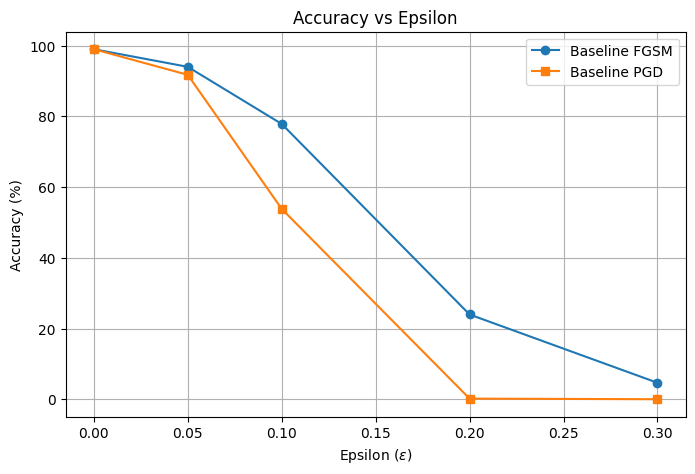

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accs, label='Baseline FGSM', marker='o')
plt.plot(epsilons, pgd_accs, label='Baseline PGD', marker='s')
plt.xlabel('Epsilon ($\epsilon$)')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy vs Epsilon')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_vs_epsilon.png')
plt.show()